In [1]:
#Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

Matplotlib is building the font cache; this may take a moment.


In [2]:
#1. Load Cleaned Dataset

BASE_DIR = Path.cwd().parent
DATA_FILE = BASE_DIR / "outputs" / "cleaned_campaign_data.csv"

df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (161248, 17)


In [3]:
#First Look

df.head()

,Campaign_ID,Brand_Name,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
0,TI-CMP-1000,Tira,SEO,Working Women,11.00,Unknown,"64,004.00","2,906.00","1,639.00",952.00,"222,768.00",129.72,"1,716.30",Tamil,13.57,Premium Shoppers,2024-10-30
1,TI-CMP-1001,Tira,Social Media,Tier 2 City Customers,24.00,YouTube,"71,795.00","2,051.00",552.00,256.00,"199,168.00",316.36,628.56,Tamil,3.98,College Students,2024-09-11
2,TI-CMP-1002,Tira,Unknown,Working Women,28.00,Unknown,"79,158.00","3,546.00","1,928.00","1,314.00","433,620.00",208.62,"2,077.52",English,8.58,Tier 2 City Customers,2024-08-28
3,TI-CMP-1003,Tira,Email,Youth,8.00,Google,"31,523.00","3,721.00","2,088.00",736.00,"571,872.00",161.13,"3,548.13",Bengali,20.76,Youth,2024-07-27
4,TI-CMP-1004,Tira,Paid Ads,Premium Shoppers,15.00,"Facebook, Email, WhatsApp","61,441.00","7,277.00","3,615.00","2,602.00","1,477,936.00",82.07,"18,007.24",Tamil,21.96,College Students,2024-12-19


In [4]:
#Last Records

df.tail()

,Campaign_ID,Brand_Name,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
161243,PU-CMP-56550,Purplle,SEO,Premium Shoppers,10.00,"WhatsApp, Instagram","58,191.00","7,763.00","3,471.00","2,132.00","1,097,980.00",73.52,"14,933.44",Tamil,22.97,Youth,2025-05-08
161244,PU-CMP-56551,Purplle,Email,Tier 2 City Customers,12.00,"YouTube, Google","85,085.00","8,986.00","4,096.00","2,308.00","800,876.00",53.17,"15,061.55",Tamil,18.09,College Students,2024-08-23
161245,PU-CMP-56552,Purplle,Email,College Students,29.00,"YouTube, Google, Email","66,094.00","4,051.00","2,155.00","1,307.00","414,319.00",113.10,"3,662.30",Bengali,13.58,Unknown,2024-11-09
161246,PU-CMP-56553,Purplle,Paid Ads,College Students,7.00,"Facebook, WhatsApp","65,050.00","5,196.00","2,263.00","1,235.00","737,295.00",237.80,"3,099.48",Hindi,13.37,Youth,2024-09-30
161247,PU-CMP-56554,Purplle,Social Media,College Students,25.00,"Facebook, Instagram, Email","19,137.00","1,529.00",512.00,303.00,"154,227.00",252.94,608.74,Hindi,12.25,Premium Shoppers,2024-11-04


In [5]:
#Dataset Information

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("\nShape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)



DATASET INFORMATION

Shape: (161248, 17)

Columns:
['Campaign_ID', 'Brand_Name', 'Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 'Impressions', 'Clicks', 'Leads', 'Conversions', 'Revenue', 'Acquisition_Cost', 'ROI', 'Language', 'Engagement_Score', 'Customer_Segment', 'Date']

Data Types:
Campaign_ID             str
Brand_Name              str
Campaign_Type           str
Target_Audience         str
Duration            float64
Channel_Used            str
Impressions         float64
Clicks              float64
Leads               float64
Conversions         float64
Revenue             float64
Acquisition_Cost    float64
ROI                 float64
Language                str
Engagement_Score    float64
Customer_Segment        str
Date                    str
dtype: object


In [6]:
#Missing Values and Duplicates

print("=" * 70)
print("DATA QUALITY CHECK")
print("=" * 70)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

DATA QUALITY CHECK

Missing Values:
Campaign_ID         0
Brand_Name          0
Campaign_Type       0
Target_Audience     0
Duration            0
Channel_Used        0
Impressions         0
Clicks              0
Leads               0
Conversions         0
Revenue             0
Acquisition_Cost    0
ROI                 0
Language            0
Engagement_Score    0
Customer_Segment    0
Date                0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0


In [7]:
#Descriptive Statistics

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Duration,"161,248.00",17.48,7.31,5.00,11.00,17.00,24.00,30.00
Impressions,"161,248.00","55,075.96","25,310.48","10,001.00","33,788.75","55,132.00","76,433.25","100,000.00"
Clicks,"161,248.00","4,646.95","3,102.54",202.00,"2,185.00","3,909.00","6,509.25","14,944.00"
Leads,"161,248.00","1,853.48","1,398.17",48.00,810.00,"1,476.00","2,525.00","8,876.00"
Conversions,"161,248.00","1,016.83",838.97,18.00,417.00,777.00,"1,358.00","6,686.00"
Revenue,"161,248.00","506,361.43","476,775.08","3,895.00","185,600.00","359,283.50","659,417.50","4,579,910.00"
Acquisition_Cost,"161,248.00",368.24,523.43,8.18,111.02,208.62,410.29,"15,473.16"
ROI,"161,248.00","6,069.58","13,748.58",-0.74,485.46,"1,748.00","5,616.53","494,114.40"
Engagement_Score,"161,248.00",13.76,6.17,2.56,8.65,13.58,18.53,30.99


In [8]:
df.describe()

,Duration,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Engagement_Score
count,"161,248.00","161,248.00","161,248.00","161,248.00","161,248.00","161,248.00","161,248.00","161,248.00","161,248.00"
mean,17.48,"55,075.96","4,646.95","1,853.48","1,016.83","506,361.43",368.24,"6,069.58",13.76
std,7.31,"25,310.48","3,102.54","1,398.17",838.97,"476,775.08",523.43,"13,748.58",6.17
min,5.00,"10,001.00",202.00,48.00,18.00,"3,895.00",8.18,-0.74,2.56
25%,11.00,"33,788.75","2,185.00",810.00,417.00,"185,600.00",111.02,485.46,8.65
50%,17.00,"55,132.00","3,909.00","1,476.00",777.00,"359,283.50",208.62,"1,748.00",13.58
75%,24.00,"76,433.25","6,509.25","2,525.00","1,358.00","659,417.50",410.29,"5,616.53",18.53
max,30.00,"100,000.00","14,944.00","8,876.00","6,686.00","4,579,910.00","15,473.16","494,114.40",30.99


3. Campaign Performance Across Brands

Brand_Name
Nykaa      55555
Purplle    52871
Tira       52822
Name: count, dtype: int64


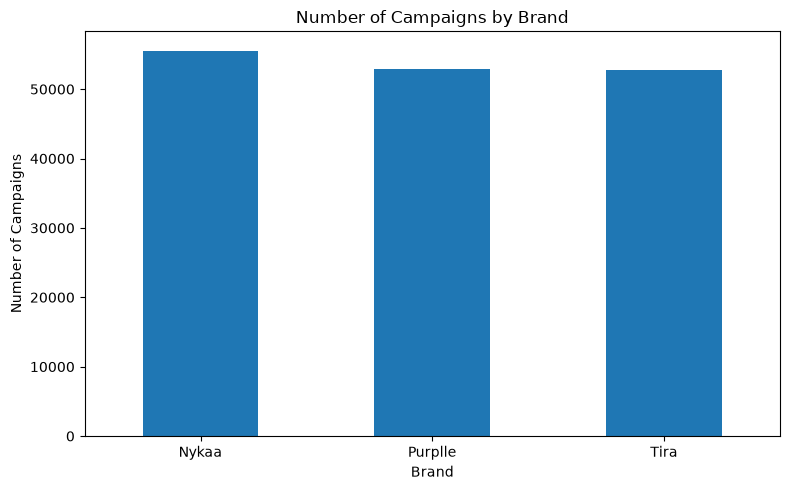

In [9]:
#Number of Campaigns by Brand

brand_campaigns = df["Brand_Name"].value_counts()

print(brand_campaigns)

#Visualization

plt.figure(figsize=(8, 5))

brand_campaigns.plot(kind="bar")

plt.title("Number of Campaigns by Brand")
plt.xlabel("Brand")
plt.ylabel("Number of Campaigns")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
#Brand-Wise Performance Summary

brand_performance = df.groupby("Brand_Name").agg(
    Campaigns=("Campaign_ID", "count"),
    Impressions=("Impressions", "sum"),
    Clicks=("Clicks", "sum"),
    Leads=("Leads", "sum"),
    Conversions=("Conversions", "sum"),
    Revenue=("Revenue", "sum"),
    Acquisition_Cost=("Acquisition_Cost", "sum"),
    Average_ROI=("ROI", "mean"),
    Median_ROI=("ROI", "median"),
    Average_Engagement=("Engagement_Score", "mean")
).sort_values("Revenue", ascending=False)

brand_performance

,Campaigns,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,Average_ROI,Median_ROI,Average_Engagement
Brand_Name,,,,,,,,,,
Nykaa,55555,"3,062,351,053.00","258,413,818.00","103,167,457.00","56,727,379.00","28,209,853,001.00","20,497,642.83","6,108.20","1,753.74",13.77
Purplle,52871,"2,912,262,875.00","245,577,726.00","98,028,712.00","53,684,898.50","26,757,269,881.00","19,520,095.34","6,049.25","1,738.07",13.75
Tira,52822,"2,906,273,801.00","245,320,289.00","97,673,246.00","53,549,369.00","26,682,645,391.00","19,360,866.15","6,049.33","1,751.28",13.75


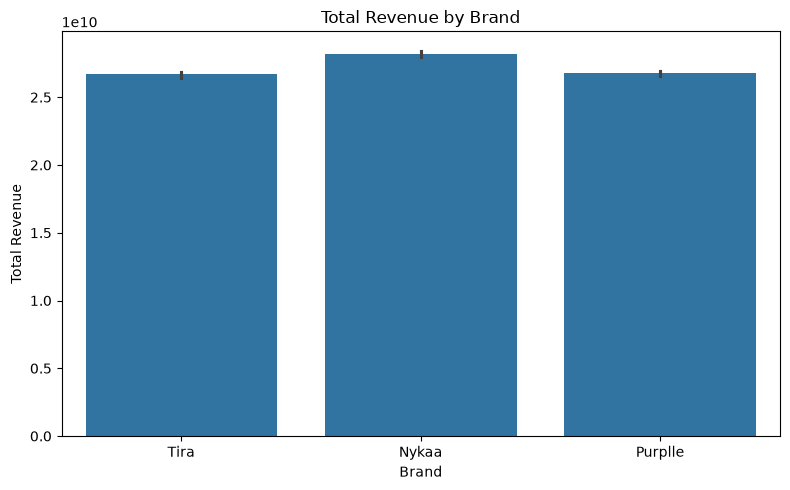

In [11]:
#Revenue by Brand

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Brand_Name",
    y="Revenue",
    estimator="sum"
)

plt.title("Total Revenue by Brand")
plt.xlabel("Brand")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

Brand_Name
Nykaa     1,753.74
Tira      1,751.28
Purplle   1,738.07
Name: ROI, dtype: float64


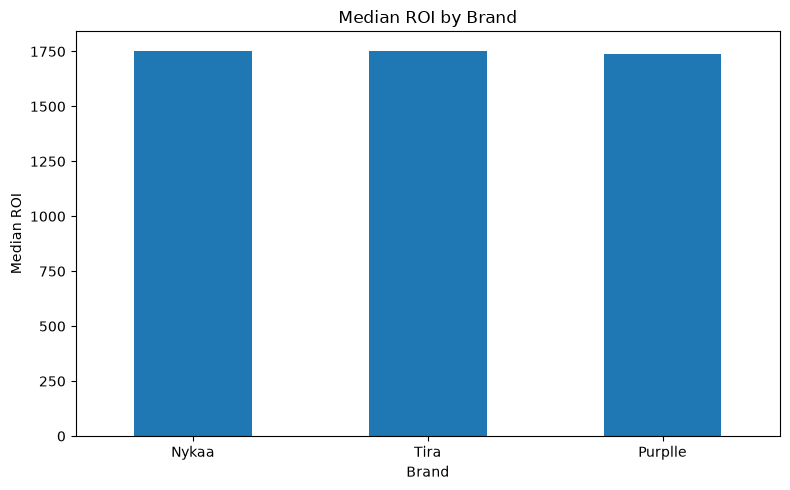

In [13]:
#ROI by Brand

brand_roi = (
    df.groupby("Brand_Name")["ROI"]
    .median()
    .sort_values(ascending=False)
)

print(brand_roi)

plt.figure(figsize=(8, 5))

brand_roi.plot(kind="bar")

plt.title("Median ROI by Brand")
plt.xlabel("Brand")
plt.ylabel("Median ROI")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



Brand_Name
Nykaa     13.77
Tira      13.75
Purplle   13.75
Name: Engagement_Score, dtype: float64


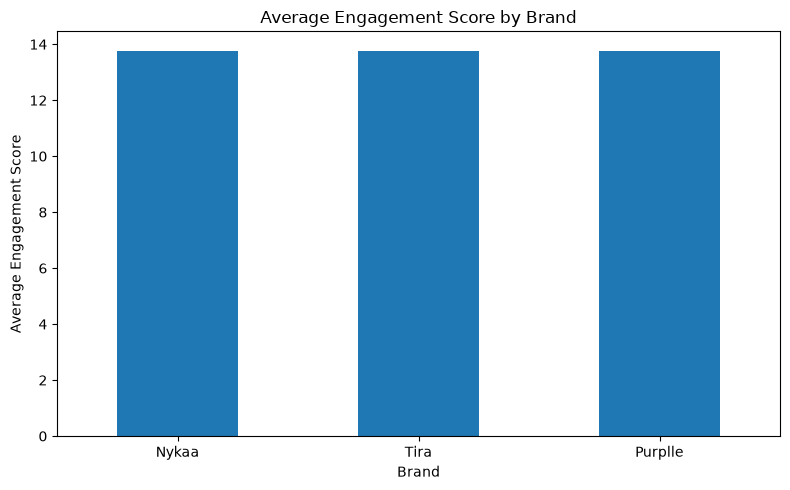

In [14]:
#Engagement by Brand

brand_engagement = (
    df.groupby("Brand_Name")["Engagement_Score"]
    .mean()
    .sort_values(ascending=False)
)

print(brand_engagement)

plt.figure(figsize=(8, 5))

brand_engagement.plot(kind="bar")

plt.title("Average Engagement Score by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Engagement Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

4. Top-Performing and Low-Performing Campaigns

In [15]:
#Top 10 Campaigns by Revenue

top_revenue_campaigns = (
    df.sort_values("Revenue", ascending=False)
    [
        [
            "Campaign_ID",
            "Brand_Name",
            "Campaign_Type",
            "Channel_Used",
            "Clicks",
            "Conversions",
            "Revenue",
            "Acquisition_Cost",
            "ROI"
        ]
    ]
    .head(10)
)

top_revenue_campaigns

,Campaign_ID,Brand_Name,Campaign_Type,Channel_Used,Clicks,Conversions,Revenue,Acquisition_Cost,ROI
64829,NY-CMP-13007,Nykaa,Paid Ads,"Email, YouTube, Facebook","14,620.00","6,686.00","4,579,910.00",207.23,"22,099.61"
39240,TI-CMP-42309,Tira,Paid Ads,YouTube,"13,757.00","5,661.00","4,517,478.00",44.89,"100,633.40"
95979,NY-CMP-44157,Nykaa,SEO,YouTube,"14,025.00","5,607.00","4,412,709.00",18.08,"244,064.76"
128602,PU-CMP-22268,Purplle,Paid Ads,"WhatsApp, YouTube","13,182.00","6,036.00","4,345,920.00",33.45,"129,921.87"
90201,NY-CMP-38379,Nykaa,Influencer,Instagram,"13,491.00","5,910.00","4,326,120.00",50.76,"85,225.95"
31091,TI-CMP-33733,Tira,SEO,"Facebook, WhatsApp","14,126.00","5,820.00","4,277,700.00",47.03,"90,955.84"
49229,TI-CMP-52788,Tira,Influencer,"Facebook, Email","11,889.00","5,309.00","4,231,273.00",208.62,"20,281.20"
25462,TI-CMP-27796,Tira,Email,"YouTube, Google","14,654.00","5,788.00","4,207,876.00",35.83,"117,439.02"
141969,PU-CMP-36294,Purplle,Influencer,Instagram,"12,930.00","5,379.00","4,195,620.00",20.35,"206,171.97"
45983,TI-CMP-49375,Tira,Social Media,Email,"14,083.00","6,383.00","4,187,248.00",36.31,"115,318.42"


In [16]:
#Lowest 10 Campaigns by Revenue

low_revenue_campaigns = (
    df.sort_values("Revenue", ascending=True)
    [
        [
            "Campaign_ID",
            "Brand_Name",
            "Campaign_Type",
            "Channel_Used",
            "Clicks",
            "Conversions",
            "Revenue",
            "Acquisition_Cost",
            "ROI"
        ]
    ]
    .head(10)
)

low_revenue_campaigns

,Campaign_ID,Brand_Name,Campaign_Type,Channel_Used,Clicks,Conversions,Revenue,Acquisition_Cost,ROI
26636,TI-CMP-29039,Tira,Email,Email,274.00,19.00,"3,895.00","15,038.00",-0.74
124454,PU-CMP-17910,Purplle,SEO,"Email, WhatsApp, YouTube",414.00,29.00,"6,061.00","4,521.07",0.34
18753,TI-CMP-20738,Tira,Influencer,"Instagram, WhatsApp, Email",316.00,22.00,"6,072.00","12,723.55",-0.52
76228,NY-CMP-24406,Nykaa,Paid Ads,"Facebook, YouTube",269.00,27.00,"6,183.00","6,805.56",-0.09
20244,TI-CMP-22313,Tira,Paid Ads,Instagram,272.00,24.00,"6,240.00","5,152.33",0.21
122583,PU-CMP-15953,Purplle,Email,"YouTube, Facebook, Email",299.00,29.00,"6,902.00","2,040.38",2.38
13553,TI-CMP-15259,Tira,Social Media,"WhatsApp, Facebook, YouTube",217.00,35.00,"7,245.00","1,975.20",2.67
130978,PU-CMP-24764,Purplle,Influencer,Unknown,249.00,35.00,"7,350.00","7,850.57",-0.06
136621,PU-CMP-30673,Purplle,Email,"Facebook, Google",228.00,35.00,"7,455.00","4,104.80",0.82
79184,NY-CMP-27362,Nykaa,Paid Ads,"YouTube, Google, Instagram",317.00,28.00,"7,476.00","3,845.96",0.94


In [17]:
#Top 10 Campaigns by ROI

top_roi_campaigns = (
    df.sort_values("ROI", ascending=False)
    [
        [
            "Campaign_ID",
            "Brand_Name",
            "Campaign_Type",
            "Channel_Used",
            "Revenue",
            "Acquisition_Cost",
            "ROI"
        ]
    ]
    .head(10)
)

top_roi_campaigns

,Campaign_ID,Brand_Name,Campaign_Type,Channel_Used,Revenue,Acquisition_Cost,ROI
43148,TI-CMP-46406,Tira,Social Media,"Google, Instagram","4,041,864.00",8.18,"494,114.40"
74511,NY-CMP-22689,Nykaa,Influencer,"Instagram, YouTube","3,821,485.00",10.68,"357,815.95"
147345,PU-CMP-41973,Purplle,Paid Ads,Instagram,"3,467,292.00",9.99,"347,075.28"
153467,PU-CMP-48391,Purplle,Influencer,"Facebook, YouTube","4,082,655.00",12.43,"328,450.73"
136153,PU-CMP-30181,Purplle,SEO,WhatsApp,"3,278,224.00",10.19,"321,708.91"
133088,PU-CMP-26973,Purplle,Social Media,"WhatsApp, YouTube","3,589,581.00",11.48,"312,680.27"
111616,PU-CMP-4412,Purplle,Email,"WhatsApp, Instagram, Facebook","2,914,444.00",9.34,"312,037.97"
78178,NY-CMP-26356,Nykaa,Paid Ads,Facebook,"3,363,384.00",10.84,"310,274.28"
57558,NY-CMP-5736,Nykaa,Email,WhatsApp,"3,036,187.00",9.85,"308,241.34"
101537,NY-CMP-49715,Nykaa,Paid Ads,WhatsApp,"3,717,208.00",12.08,"307,714.89"


In [18]:
#Lowest 10 Campaigns by ROI

low_roi_campaigns = (
    df.sort_values("ROI", ascending=True)
    [
        [
            "Campaign_ID",
            "Brand_Name",
            "Campaign_Type",
            "Channel_Used",
            "Revenue",
            "Acquisition_Cost",
            "ROI"
        ]
    ]
    .head(10)
)

low_roi_campaigns

,Campaign_ID,Brand_Name,Campaign_Type,Channel_Used,Revenue,Acquisition_Cost,ROI
26636,TI-CMP-29039,Tira,Email,Email,"3,895.00","15,038.00",-0.74
18753,TI-CMP-20738,Tira,Influencer,"Instagram, WhatsApp, Email","6,072.00","12,723.55",-0.52
68405,NY-CMP-16583,Nykaa,Paid Ads,"Google, Instagram","8,920.00","12,423.65",-0.28
116220,PU-CMP-9267,Purplle,Influencer,Instagram,"9,702.00","12,109.05",-0.20
76228,NY-CMP-24406,Nykaa,Paid Ads,"Facebook, YouTube","6,183.00","6,805.56",-0.09
86146,NY-CMP-34324,Nykaa,Paid Ads,Instagram,"14,079.00","15,473.16",-0.09
125965,PU-CMP-19502,Purplle,Influencer,"YouTube, WhatsApp, Facebook","9,315.00","9,978.26",-0.07
130978,PU-CMP-24764,Purplle,Influencer,Unknown,"7,350.00","7,850.57",-0.06
153364,PU-CMP-48283,Purplle,Social Media,"Facebook, WhatsApp","10,422.00","10,960.59",-0.05
10455,TI-CMP-12004,Tira,Social Media,YouTube,"9,425.00","9,616.32",-0.02


5. Spend, Clicks, Revenue and ROI Relationships

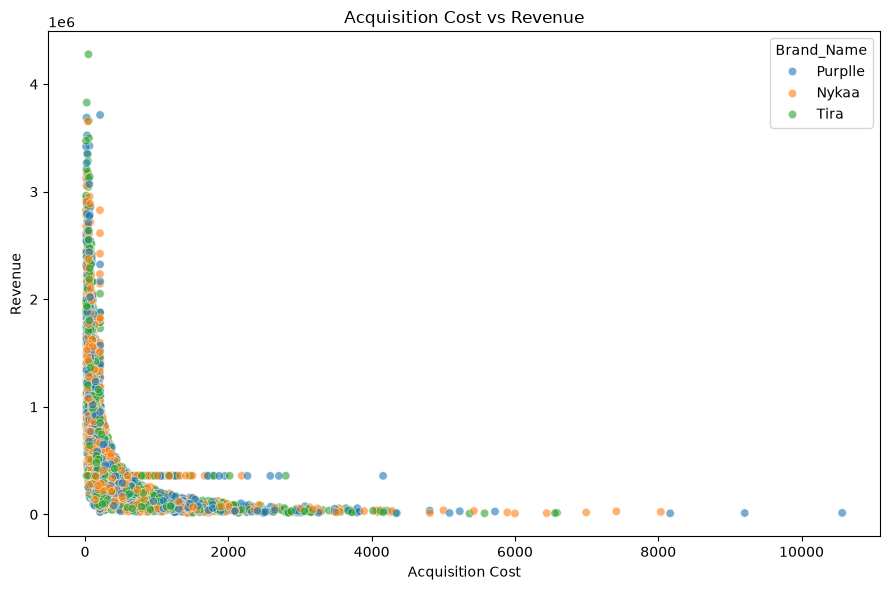

In [21]:
#Spend vs Revenue

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df.sample(min(10000, len(df)), random_state=42),
    x="Acquisition_Cost",
    y="Revenue",
    hue="Brand_Name",
    alpha=0.6
)

plt.title("Acquisition Cost vs Revenue")
plt.xlabel("Acquisition Cost")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

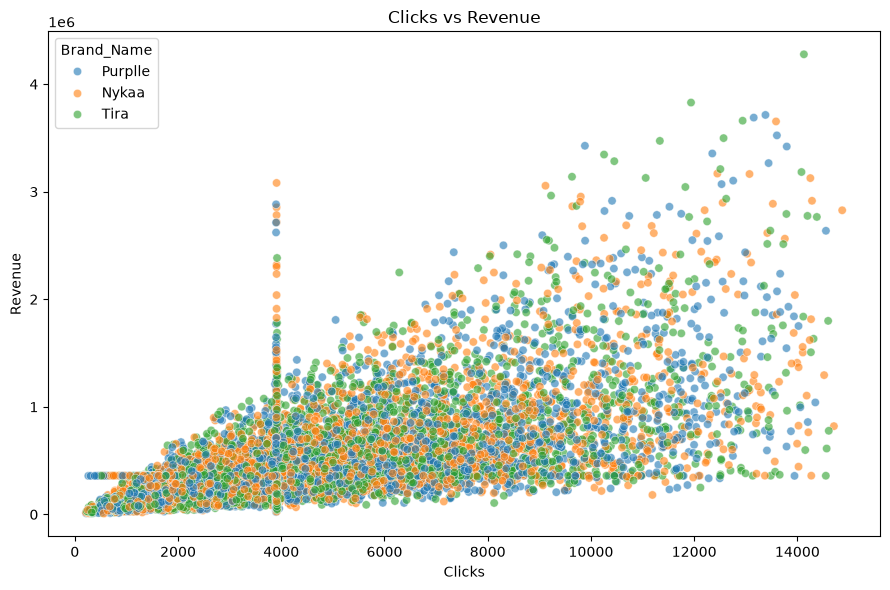

In [22]:
#Clicks vs Revenue

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df.sample(min(10000, len(df)), random_state=42),
    x="Clicks",
    y="Revenue",
    hue="Brand_Name",
    alpha=0.6
)

plt.title("Clicks vs Revenue")
plt.xlabel("Clicks")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

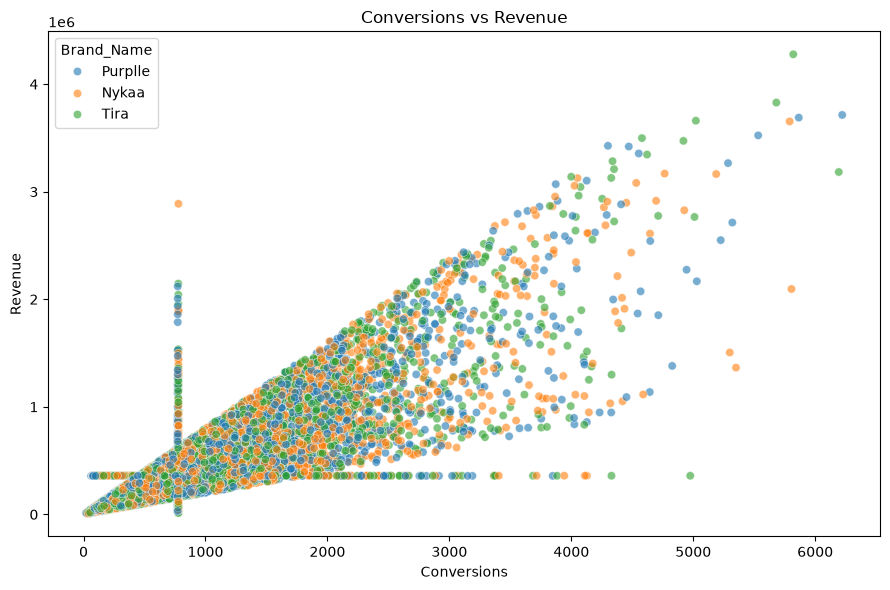

In [23]:
#Conversions vs Revenue

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df.sample(min(10000, len(df)), random_state=42),
    x="Conversions",
    y="Revenue",
    hue="Brand_Name",
    alpha=0.6
)

plt.title("Conversions vs Revenue")
plt.xlabel("Conversions")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

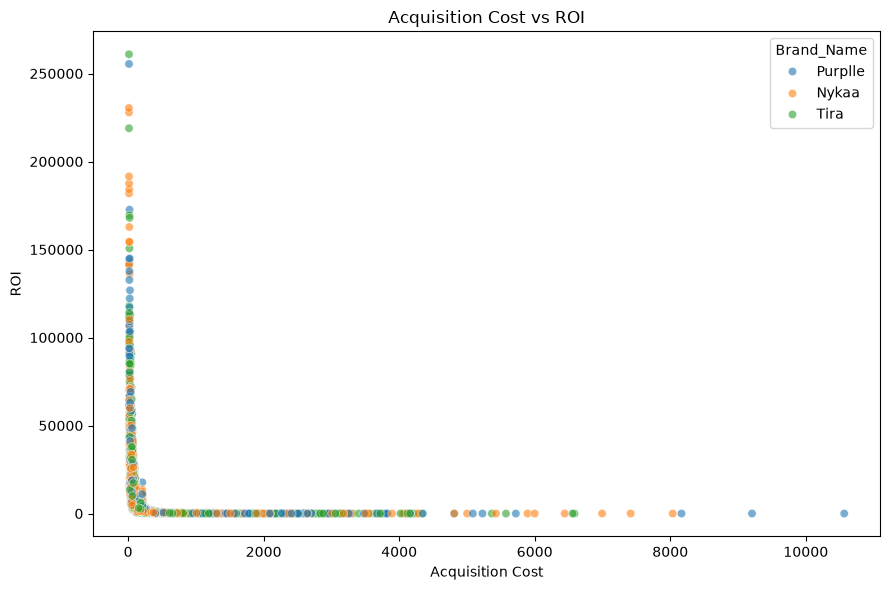

In [24]:
#Acquisition Cost vs ROI

plt.figure(figsize=(9, 6))

plot_df = df.sample(min(10000, len(df)), random_state=42)

sns.scatterplot(
    data=plot_df,
    x="Acquisition_Cost",
    y="ROI",
    hue="Brand_Name",
    alpha=0.6
)

plt.title("Acquisition Cost vs ROI")
plt.xlabel("Acquisition Cost")
plt.ylabel("ROI")
plt.tight_layout()
plt.show()

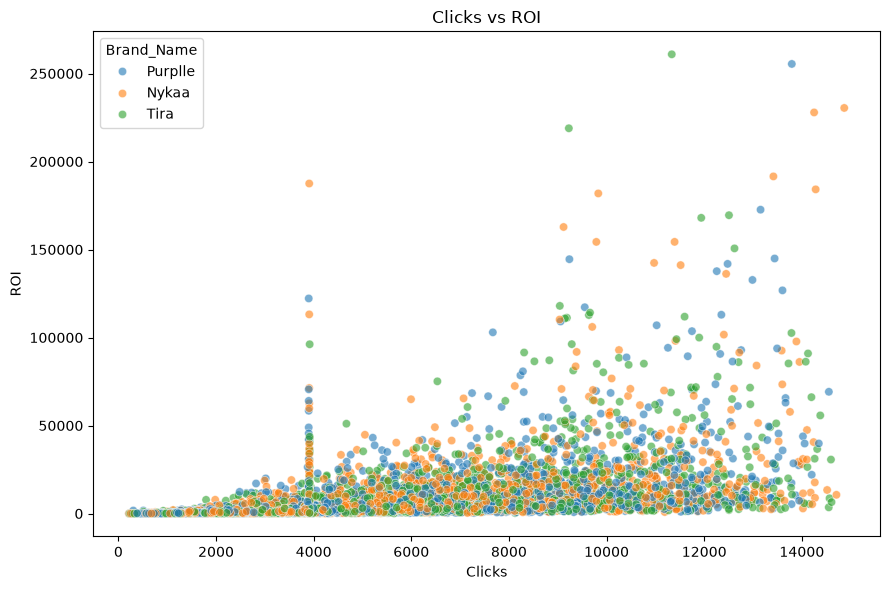

In [25]:
#Clicks vs ROI

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df.sample(min(10000, len(df)), random_state=42),
    x="Clicks",
    y="ROI",
    hue="Brand_Name",
    alpha=0.6
)

plt.title("Clicks vs ROI")
plt.xlabel("Clicks")
plt.ylabel("ROI")
plt.tight_layout()
plt.show()

6. Correlation Analysis

In [26]:
#Correlation Matrix

correlation_columns = [
    "Impressions",
    "Clicks",
    "Leads",
    "Conversions",
    "Revenue",
    "Acquisition_Cost",
    "ROI",
    "Engagement_Score"
]

correlation_matrix = df[correlation_columns].corr()

correlation_matrix

,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Engagement_Score
Impressions,1.00,0.66,0.59,0.54,0.47,-0.41,0.33,0.00
Clicks,0.66,1.00,0.84,0.77,0.68,-0.46,0.50,0.59
Leads,0.59,0.84,1.00,0.87,0.76,-0.45,0.60,0.63
Conversions,0.54,0.77,0.87,1.00,0.83,-0.44,0.69,0.61
Revenue,0.47,0.68,0.76,0.83,1.00,-0.38,0.77,0.54
Acquisition_Cost,-0.41,-0.46,-0.45,-0.44,-0.38,1.00,-0.24,-0.40
ROI,0.33,0.50,0.60,0.69,0.77,-0.24,1.00,0.40
Engagement_Score,0.00,0.59,0.63,0.61,0.54,-0.40,0.40,1.00


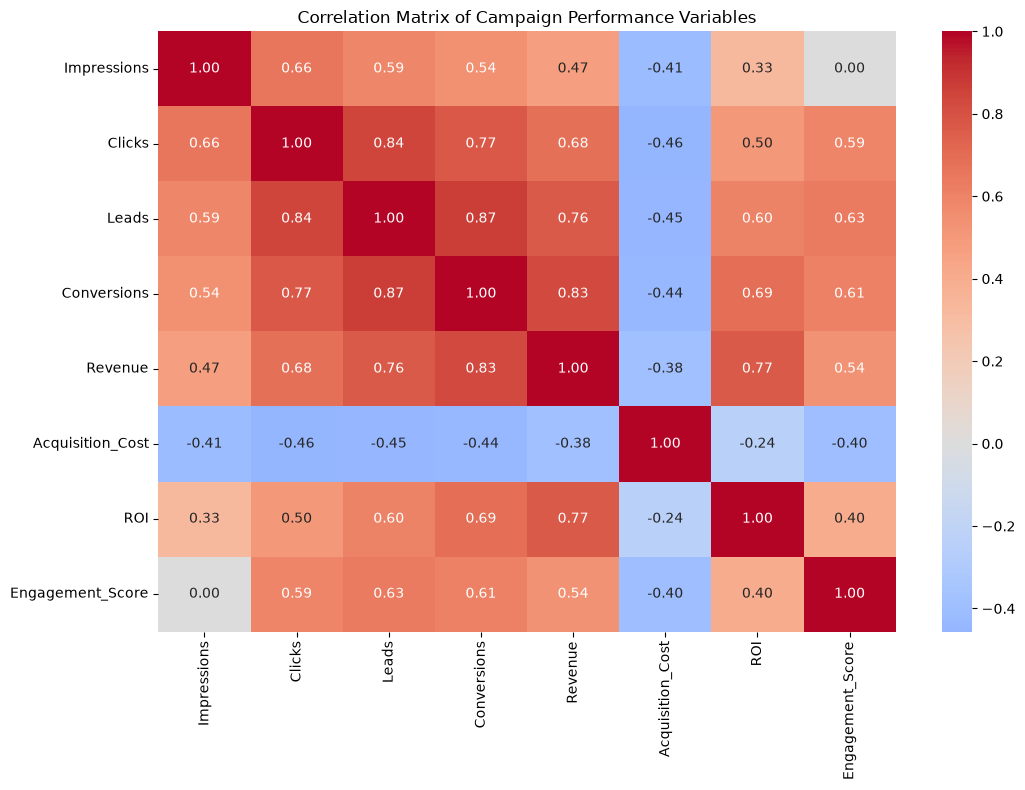

In [27]:
#Correlation Heatmap

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Campaign Performance Variables")
plt.tight_layout()
plt.show()

In [28]:
#Correlation with Revenue

revenue_correlation = (
    correlation_matrix["Revenue"]
    .sort_values(ascending=False)
)

print("Correlation with Revenue:")
print(revenue_correlation)

Correlation with Revenue:
Revenue             1.00
Conversions         0.83
ROI                 0.77
Leads               0.76
Clicks              0.68
Engagement_Score    0.54
Impressions         0.47
Acquisition_Cost   -0.38
Name: Revenue, dtype: float64


In [29]:
#Correlation with ROI

roi_correlation = (
    correlation_matrix["ROI"]
    .sort_values(ascending=False)
)

print("Correlation with ROI:")
print(roi_correlation)

Correlation with ROI:
ROI                 1.00
Revenue             0.77
Conversions         0.69
Leads               0.60
Clicks              0.50
Engagement_Score    0.40
Impressions         0.33
Acquisition_Cost   -0.24
Name: ROI, dtype: float64


7. Channel-Wise Effectiveness

In [32]:
#Channel Values

print("Number of unique Channel_Used values:",
      df["Channel_Used"].nunique())

print("\nChannel values:")
print(df["Channel_Used"].value_counts().head(30))

Number of unique Channel_Used values: 157

Channel values:
Channel_Used
Email                  8661
Instagram              8569
Facebook               8499
Google                 8474
WhatsApp               8424
YouTube                8423
Unknown                7996
Email, Facebook        1776
YouTube, Instagram     1775
YouTube, WhatsApp      1761
WhatsApp, Email        1744
WhatsApp, Google       1741
WhatsApp, Instagram    1739
Google, Instagram      1739
Google, Facebook       1736
Instagram, YouTube     1735
Email, Google          1734
Email, YouTube         1724
Email, WhatsApp        1724
Instagram, Email       1723
YouTube, Email         1711
YouTube, Facebook      1709
Facebook, YouTube      1701
Google, WhatsApp       1697
Facebook, Email        1696
Facebook, Google       1690
Google, Email          1687
Instagram, WhatsApp    1685
Google, YouTube        1679
Email, Instagram       1671
Name: count, dtype: int64


In [33]:
#Channel Performance

channel_performance = df.groupby("Channel_Used").agg(
    Campaigns=("Campaign_ID", "count"),
    Impressions=("Impressions", "sum"),
    Clicks=("Clicks", "sum"),
    Leads=("Leads", "sum"),
    Conversions=("Conversions", "sum"),
    Revenue=("Revenue", "sum"),
    Acquisition_Cost=("Acquisition_Cost", "sum"),
    Average_ROI=("ROI", "mean"),
    Median_ROI=("ROI", "median"),
    Average_Engagement=("Engagement_Score", "mean")
).sort_values("Revenue", ascending=False)

channel_performance

,Campaigns,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,Average_ROI,Median_ROI,Average_Engagement
Channel_Used,,,,,,,,,,
Email,8661,"478,301,610.50","40,463,041.00","16,279,921.00","8,905,389.50","4,489,533,957.50","3,144,575.04","6,328.64","1,801.46",13.91
Instagram,8569,"472,453,475.00","40,179,463.00","15,989,663.00","8,822,778.50","4,342,367,786.00","3,104,637.87","5,974.60","1,820.62",13.84
Facebook,8499,"468,707,147.50","39,605,445.00","15,743,763.00","8,641,819.50","4,297,710,370.50","3,111,478.34","6,032.06","1,735.39",13.67
WhatsApp,8424,"464,437,134.50","39,292,607.00","15,679,149.00","8,652,994.50","4,271,619,589.50","3,121,256.14","6,243.38","1,739.04",13.74
Google,8474,"466,633,801.50","39,416,212.00","15,620,409.00","8,553,581.50","4,268,320,237.00","3,116,176.60","6,009.35","1,736.48",13.78
...,...,...,...,...,...,...,...,...,...,...
"Email, Google, YouTube",375,"20,326,171.50","1,714,523.00","690,657.00","388,947.00","189,699,154.00","134,696.62","5,844.25","1,752.44",13.62
"WhatsApp, Email, YouTube",410,"21,729,636.50","1,804,493.00","701,013.00","382,990.50","187,850,276.50","163,768.49","5,313.02","1,481.34",13.52
"Email, Facebook, Instagram",390,"20,798,939.00","1,796,891.00","697,593.00","393,871.50","187,512,192.00","136,825.15","5,632.82","1,643.44",13.74


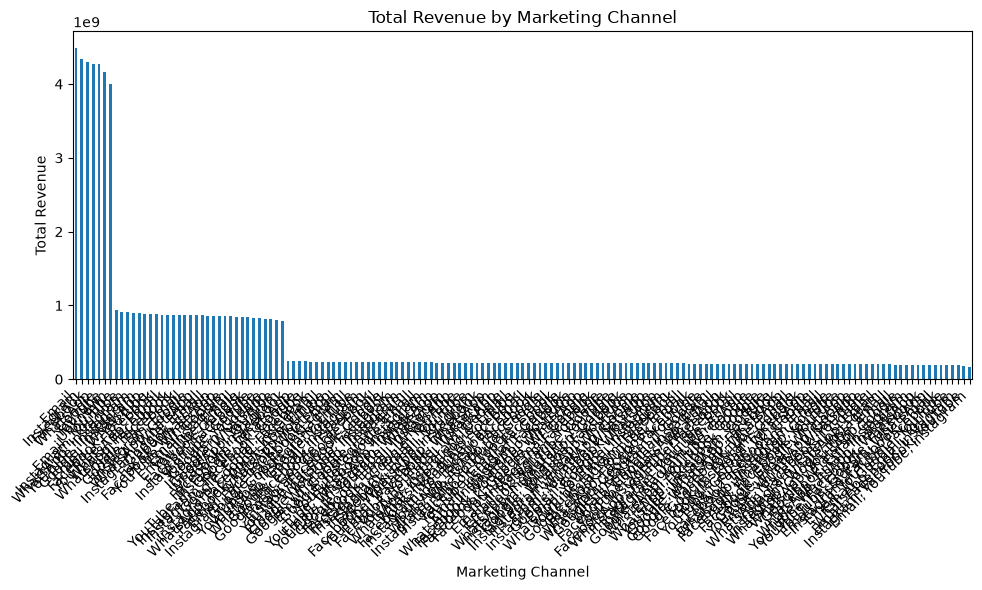

In [53]:
#Total Revenue by Marketing Channel

plt.figure(figsize=(10, 6))

channel_revenue = (
    df.groupby("Channel_Used")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

channel_revenue.plot(kind="bar")

plt.title("Total Revenue by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

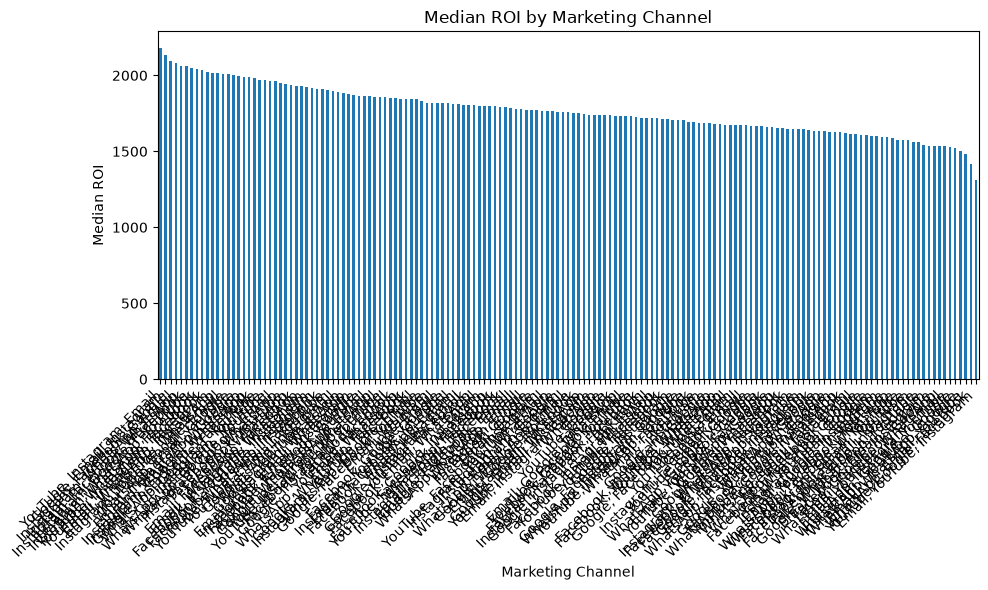

In [54]:
#Median ROI by Channel

plt.figure(figsize=(10, 6))

channel_roi = (
    df.groupby("Channel_Used")["ROI"]
    .median()
    .sort_values(ascending=False)
)

channel_roi.plot(kind="bar")

plt.title("Median ROI by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Median ROI")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

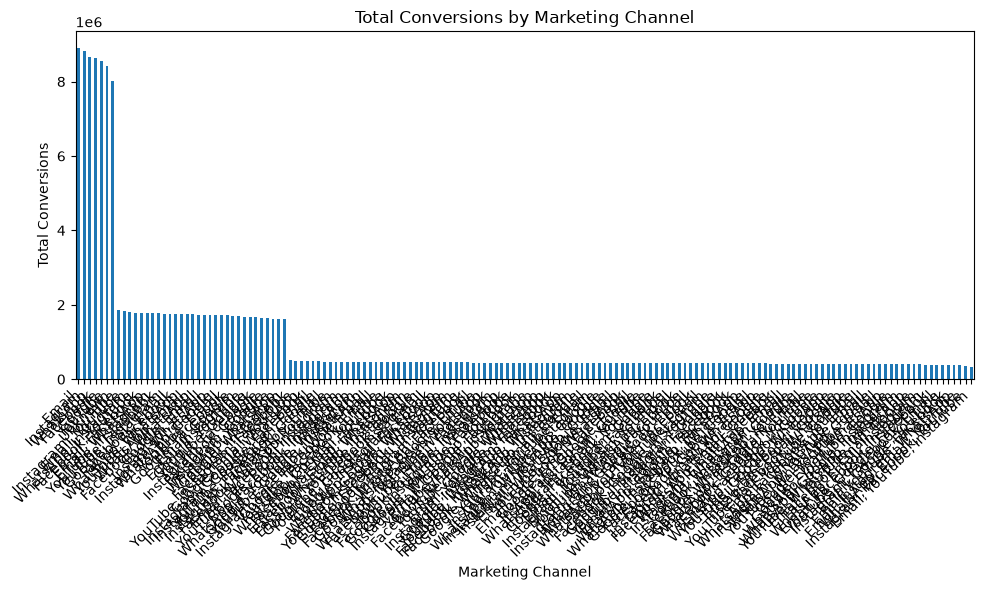

In [55]:
#Conversions by Channel

plt.figure(figsize=(10, 6))

channel_conversions = (
    df.groupby("Channel_Used")["Conversions"]
    .sum()
    .sort_values(ascending=False)
)

channel_conversions.plot(kind="bar")

plt.title("Total Conversions by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Total Conversions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



8. Campaign Type Analysis

In [40]:
#Campaign Type Performance

campaign_type_performance = df.groupby("Campaign_Type").agg(
    Campaigns=("Campaign_ID", "count"),
    Revenue=("Revenue", "sum"),
    Acquisition_Cost=("Acquisition_Cost", "sum"),
    Clicks=("Clicks", "sum"),
    Conversions=("Conversions", "sum"),
    Median_ROI=("ROI", "median"),
    Average_Engagement=("Engagement_Score", "mean")
).sort_values("Revenue", ascending=False)

campaign_type_performance

,Campaigns,Revenue,Acquisition_Cost,Clicks,Conversions,Median_ROI,Average_Engagement
Campaign_Type,,,,,,,
Email,30754,"15,607,940,133.50","11,358,532.73","142,646,638.00","31,272,064.00","1,746.39",13.74
Paid Ads,30565,"15,588,772,628.50","11,144,510.23","142,466,120.00","31,210,788.00","1,792.83",13.76
Influencer,30743,"15,495,700,445.00","11,386,092.78","142,722,643.00","31,163,282.00","1,735.39",13.81
Social Media,30488,"15,474,900,096.50","11,129,094.01","142,380,939.00","31,203,470.00","1,736.69",13.80
SEO,30590,"15,361,434,421.50","11,333,925.86","141,591,856.00","30,836,391.00","1,725.00",13.70
Unknown,8108,"4,121,020,548.00","3,026,448.71","37,503,637.00","8,275,651.50","1,763.06",13.69


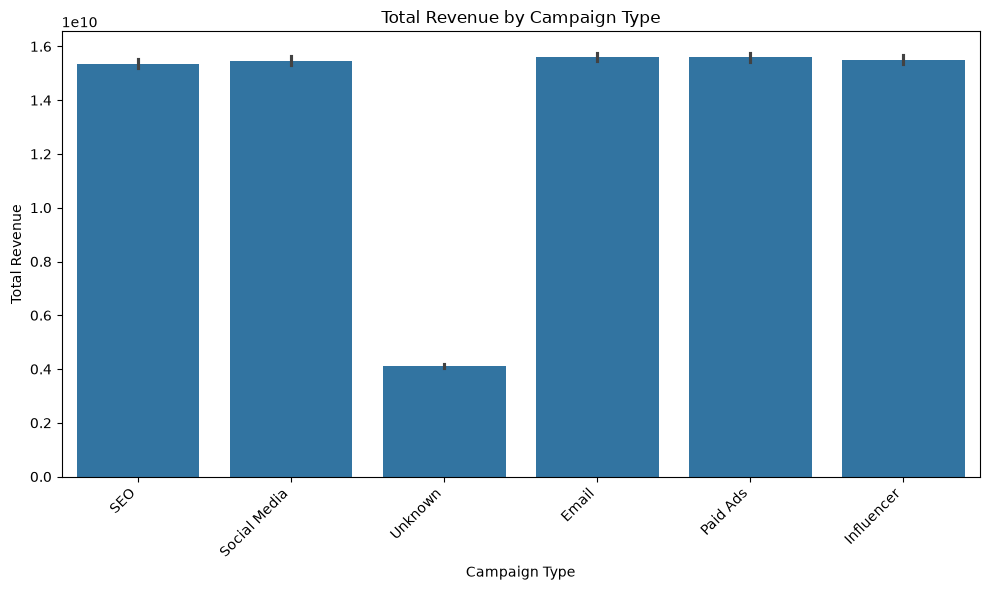

In [41]:
#Revenue by Campaign Type

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Campaign_Type",
    y="Revenue",
    estimator="sum"
)

plt.title("Total Revenue by Campaign Type")
plt.xlabel("Campaign Type")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

9. Conversion Funnel Analysis

In [42]:
#Overall Funnel

funnel = pd.Series({
    "Impressions": df["Impressions"].sum(),
    "Clicks": df["Clicks"].sum(),
    "Leads": df["Leads"].sum(),
    "Conversions": df["Conversions"].sum()
})

funnel

Impressions   8,880,887,729.00
Clicks          749,311,833.00
Leads           298,869,415.00
Conversions     163,961,646.50
dtype: float64

In [43]:
#Overall Conversion Rates

total_impressions = df["Impressions"].sum()
total_clicks = df["Clicks"].sum()
total_leads = df["Leads"].sum()
total_conversions = df["Conversions"].sum()

ctr = (total_clicks / total_impressions) * 100
lead_rate = (total_leads / total_clicks) * 100
conversion_rate = (total_conversions / total_leads) * 100

print(f"Click Through Rate (CTR): {ctr:.2f}%")
print(f"Lead Rate: {lead_rate:.2f}%")
print(f"Lead-to-Conversion Rate: {conversion_rate:.2f}%")

Click Through Rate (CTR): 8.44%
Lead Rate: 39.89%
Lead-to-Conversion Rate: 54.86%


10. Brand × Channel Analysis

In [44]:
#Brand and Channel Revenue

brand_channel_revenue = pd.pivot_table(
    df,
    values="Revenue",
    index="Brand_Name",
    columns="Channel_Used",
    aggfunc="sum"
)

brand_channel_revenue

Channel_Used,Email,"Email, Facebook","Email, Facebook, Google","Email, Facebook, Instagram","Email, Facebook, WhatsApp","Email, Facebook, YouTube","Email, Google","Email, Google, Facebook","Email, Google, Instagram","Email, Google, WhatsApp","Email, Google, YouTube","Email, Instagram","Email, Instagram, Facebook","Email, Instagram, Google","Email, Instagram, WhatsApp","Email, Instagram, YouTube","Email, WhatsApp","Email, WhatsApp, Facebook","Email, WhatsApp, Google","Email, WhatsApp, Instagram","Email, WhatsApp, YouTube","Email, YouTube","Email, YouTube, Facebook","Email, YouTube, Google","Email, YouTube, Instagram","Email, YouTube, WhatsApp",Facebook,"Facebook, Email","Facebook, Email, Google","Facebook, Email, Instagram","Facebook, Email, WhatsApp","Facebook, Email, YouTube","Facebook, Google","Facebook, Google, Email","Facebook, Google, Instagram","Facebook, Google, WhatsApp","Facebook, Google, YouTube","Facebook, Instagram","Facebook, Instagram, Email","Facebook, Instagram, Google","Facebook, Instagram, WhatsApp","Facebook, Instagram, YouTube","Facebook, WhatsApp","Facebook, WhatsApp, Email","Facebook, WhatsApp, Google","Facebook, WhatsApp, Instagram","Facebook, WhatsApp, YouTube","Facebook, YouTube","Facebook, YouTube, Email","Facebook, YouTube, Google","Facebook, YouTube, Instagram","Facebook, YouTube, WhatsApp",Google,"Google, Email","Google, Email, Facebook","Google, Email, Instagram","Google, Email, WhatsApp","Google, Email, YouTube","Google, Facebook","Google, Facebook, Email","Google, Facebook, Instagram","Google, Facebook, WhatsApp","Google, Facebook, YouTube","Google, Instagram","Google, Instagram, Email","Google, Instagram, Facebook","Google, Instagram, WhatsApp","Google, Instagram, YouTube","Google, WhatsApp","Google, WhatsApp, Email","Google, WhatsApp, Facebook","Google, WhatsApp, Instagram","Google, WhatsApp, YouTube","Google, YouTube","Google, YouTube, Email","Google, YouTube, Facebook","Google, YouTube, Instagram","Google, YouTube, WhatsApp",Instagram,"Instagram, Email","Instagram, Email, Facebook","Instagram, Email, Google","Instagram, Email, WhatsApp","Instagram, Email, YouTube","Instagram, Facebook","Instagram, Facebook, Email","Instagram, Facebook, Google","Instagram, Facebook, WhatsApp","Instagram, Facebook, YouTube","Instagram, Google","Instagram, Google, Email","Instagram, Google, Facebook","Instagram, Google, WhatsApp","Instagram, Google, YouTube","Instagram, WhatsApp","Instagram, WhatsApp, Email","Instagram, WhatsApp, Facebook","Instagram, WhatsApp, Google","Instagram, WhatsApp, YouTube","Instagram, YouTube","Instagram, YouTube, Email","Instagram, YouTube, Facebook","Instagram, YouTube, Google","Instagram, YouTube, WhatsApp",Unknown,WhatsApp,"WhatsApp, Email","WhatsApp, Email, Facebook","WhatsApp, Email, Google","WhatsApp, Email, Instagram","WhatsApp, Email, YouTube","WhatsApp, Facebook","WhatsApp, Facebook, Email","WhatsApp, Facebook, Google","WhatsApp, Facebook, Instagram","WhatsApp, Facebook, YouTube","WhatsApp, Google","WhatsApp, Google, Email","WhatsApp, Google, Facebook","WhatsApp, Google, Instagram","WhatsApp, Google, YouTube","WhatsApp, Instagram","WhatsApp, Instagram, Email","WhatsApp, Instagram, Facebook","WhatsApp, Instagram, Google","WhatsApp, Instagram, YouTube","WhatsApp, YouTube","WhatsApp, YouTube, Email","WhatsApp, YouTube, Facebook","WhatsApp, YouTube, Google","WhatsApp, YouTube, Instagram",YouTube,"YouTube, Email","YouTube, Email, Facebook","YouTube, Email, Google","YouTube, Email, Instagram","YouTube, Email, WhatsApp","YouTube, Facebook","YouTube, Facebook, Email","YouTube, Facebook, Google","YouTube, Facebook, Instagram","YouTube, Facebook, WhatsApp","YouTube, Google","YouTube, Google, Email","YouTube, Google, Facebook","YouTube, Google, Instagram","YouTube, Google, WhatsApp","YouTube, Instagram","YouTube, Instagram, Email","YouTube, Instagram, Facebook","YouTube, Instagram, Google","YouTube, Instagram, WhatsApp","YouTube, WhatsApp","YouTube, WhatsApp, Email","YouTube, WhatsApp,

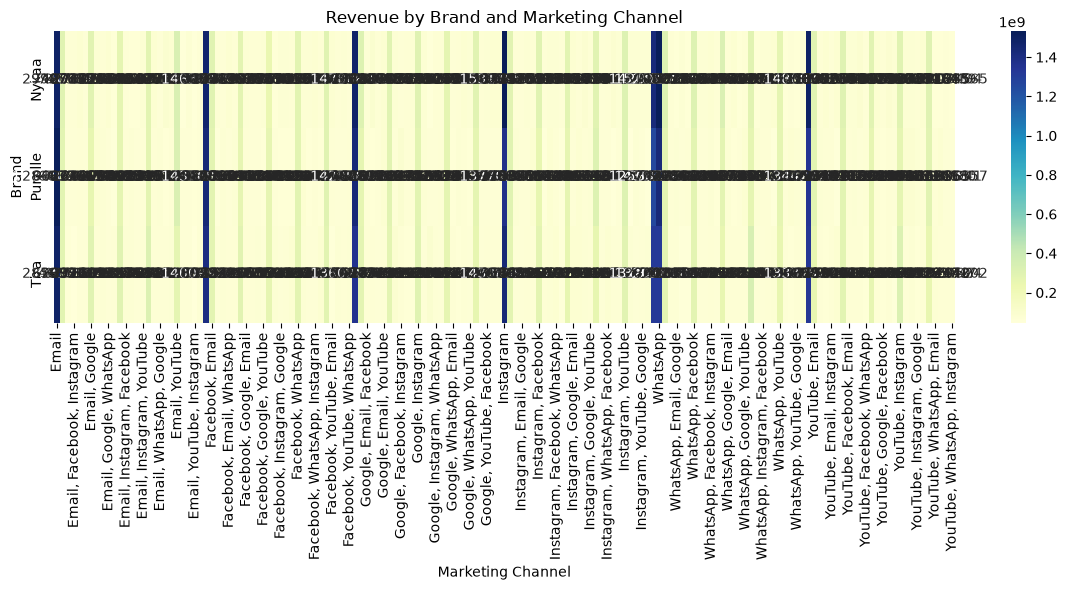

In [45]:
#Brand × Channel Heatmap

plt.figure(figsize=(12, 6))

sns.heatmap(
    brand_channel_revenue,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Revenue by Brand and Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

11. ROI Distribution

In [46]:
#ROI Statistics

print("ROI Statistics")
print("=" * 50)

print("Minimum ROI:", df["ROI"].min())
print("Maximum ROI:", df["ROI"].max())
print("Mean ROI:", df["ROI"].mean())
print("Median ROI:", df["ROI"].median())

print("\nPercentiles:")
print(df["ROI"].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

ROI Statistics
Minimum ROI: -0.741
Maximum ROI: 494114.4034
Mean ROI: 6069.582687695972
Median ROI: 1747.9967000000001

Percentiles:
0.25      485.46
0.50    1,748.00
0.75    5,616.53
0.90   15,081.17
0.95   26,165.20
0.99   65,445.05
Name: ROI, dtype: float64


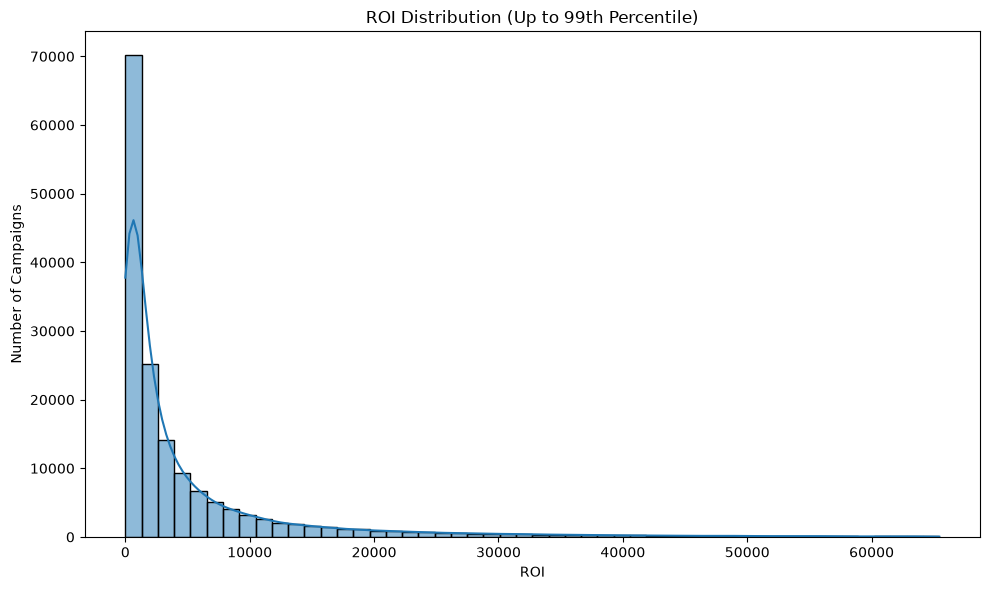

In [47]:
#ROI Distribution

roi_limit = df["ROI"].quantile(0.99)

plt.figure(figsize=(10, 6))

sns.histplot(
    df[df["ROI"] <= roi_limit]["ROI"],
    bins=50,
    kde=True
)

plt.title("ROI Distribution (Up to 99th Percentile)")
plt.xlabel("ROI")
plt.ylabel("Number of Campaigns")
plt.tight_layout()
plt.show()

12. Final EDA Summary

In [48]:
#Key Findings Tables

print("=" * 80)
print("KEY EDA SUMMARY")
print("=" * 80)

print("\n1. BRAND PERFORMANCE")
print(brand_performance)

print("\n2. TOP 10 CAMPAIGNS BY REVENUE")
print(top_revenue_campaigns)

print("\n3. TOP 10 CAMPAIGNS BY ROI")
print(top_roi_campaigns)

print("\n4. CHANNEL PERFORMANCE")
print(channel_performance)

print("\n5. CAMPAIGN TYPE PERFORMANCE")
print(campaign_type_performance)

KEY EDA SUMMARY

1. BRAND PERFORMANCE
            Campaigns      Impressions         Clicks          Leads  \
Brand_Name                                                             
Nykaa           55555 3,062,351,053.00 258,413,818.00 103,167,457.00   
Purplle         52871 2,912,262,875.00 245,577,726.00  98,028,712.00   
Tira            52822 2,906,273,801.00 245,320,289.00  97,673,246.00   

             Conversions           Revenue  Acquisition_Cost  Average_ROI  \
Brand_Name                                                                  
Nykaa      56,727,379.00 28,209,853,001.00     20,497,642.83     6,108.20   
Purplle    53,684,898.50 26,757,269,881.00     19,520,095.34     6,049.25   
Tira       53,549,369.00 26,682,645,391.00     19,360,866.15     6,049.33   

            Median_ROI  Average_Engagement  
Brand_Name                                  
Nykaa         1,753.74               13.77  
Purplle       1,738.07               13.75  
Tira          1,751.28             